# Basic GPT

A decoder only transformer written from scratch in PyTorch, following "Attention Is All You Need" and the GPT-2 design, trained on the works of Shakespeare.

What is built here:

- Token and position embeddings, multi head causal self attention, feed forward blocks, layer normalization (written by hand) and dropout.
- A training loop with gradient accumulation, a warmup plus cosine learning rate schedule, gradient clipping, mixed precision, evaluation and checkpointing.
- Text generation with temperature, top k and top p sampling.

Before training, a set of checks confirms that each part does what it should (for example, that the model cannot see future tokens). After training, the model is compared with the character bigram model from the first notebook.

The notebook picks a larger model automatically when a CUDA GPU is available and a small one on a CPU. The data file (data/input.txt) is downloaded if missing.

In [1]:
import os, math, time, inspect, re, random, urllib.request
from contextlib import nullcontext
from dataclasses import dataclass, asdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 1337
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device:", device, "| torch", torch.__version__)

os.makedirs("data", exist_ok=True)
if not os.path.exists("data/input.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "data/input.txt")
text = open("data/input.txt", encoding="utf-8").read()
print(len(text), "characters")
print(text[:250])

device: cpu | torch 2.15.0+cu132
1115394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## Data

The default is character level tokens (65 symbols). Set TOKENIZER to "bpe" to use the 512 token BPE vocabulary built in the tokenizer notebook (it reads data/shakespeare_bpe.npz). The text is split 90 percent for training and 10 percent for validation.

In [2]:
class Data:
    """Holds the token ids, the train/val split, and knows how to decode ids back to text."""
    def __init__(self, kind="char"):
        self.kind = kind
        if kind == "char":
            chars = sorted(set(text))
            self.stoi = {c: i for i, c in enumerate(chars)}
            self.itos = {i: c for c, i in self.stoi.items()}
            self.vocab_size = len(chars)
            ids = torch.tensor([self.stoi[c] for c in text], dtype=torch.long)
            self.start_ids = [self.stoi["\n"]]
        elif kind == "bpe":
            npz = np.load("data/shakespeare_bpe.npz", allow_pickle=True)
            ids = torch.from_numpy(npz["ids"].astype(np.int64))
            self.token_bytes = [t.encode("latin-1") for t in npz["vocab"]]
            self.vocab_size = len(self.token_bytes)
            self.start_ids = [10]            # the single byte token for a newline
        else:
            raise ValueError(kind)
        n = int(0.9 * len(ids))
        self.train, self.val = ids[:n], ids[n:]

    def encode(self, s):
        assert self.kind == "char", "prompt encoding is only implemented for the character level data"
        return [self.stoi[c] for c in s]

    def decode(self, ids):
        if self.kind == "char":
            return "".join(self.itos[int(i)] for i in ids)
        return b"".join(self.token_bytes[int(i)] for i in ids).decode("utf-8", errors="replace")

    def get_batch(self, split, batch_size, block_size, device=None):
        d = self.train if split == "train" else self.val
        ix = torch.randint(len(d) - block_size - 1, (batch_size,))
        x = torch.stack([d[i:i + block_size] for i in ix])
        y = torch.stack([d[i + 1:i + 1 + block_size] for i in ix])
        if device is not None:
            x, y = x.to(device), y.to(device)
        return x, y

TOKENIZER = "char"
data = Data(TOKENIZER)
print("tokenizer:", TOKENIZER, "| vocab size:", data.vocab_size, "| train tokens:", len(data.train), "| val tokens:", len(data.val))
print("round trip:", data.decode(data.train[:60].tolist()).replace("\n", "\\n"))

tokenizer: char | vocab size: 65 | train tokens: 1003854 | val tokens: 111540
round trip: First Citizen:\nBefore we proceed any further, hear me speak.


## The model

Each piece in turn.

Layer normalization normalizes every token vector to zero mean and unit variance across its features, then applies a learned scale and shift. It is written out by hand here and checked against PyTorch's version below.

In [3]:
class LayerNorm(nn.Module):
    def __init__(self, ndim, bias=True, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.bias = nn.Parameter(torch.zeros(ndim)) if bias else None
        self.eps = eps

    def forward(self, x):
        xf = x.float()                                   # do the statistics in full precision
        mean = xf.mean(-1, keepdim=True)
        var = xf.var(-1, keepdim=True, unbiased=False)
        xf = (xf - mean) / torch.sqrt(var + self.eps)
        out = xf.type_as(x) * self.weight
        return out + self.bias if self.bias is not None else out

Causal self attention. Every token produces a query, a key and a value. The score between two tokens is the dot product of one's query and the other's key, divided by the square root of the head size. A mask sets the scores for future positions to minus infinity, so after the softmax a token only mixes values from itself and earlier tokens. The heads run in parallel on slices of the embedding and their outputs are concatenated and projected.

The explicit version below is the reference. There is also a fused version (flash=True) that calls PyTorch's built in attention. A check below confirms they agree.

In [4]:
@dataclass
class GPTConfig:
    block_size: int = 256       # maximum context length
    vocab_size: int = 65
    n_layer: int = 6
    n_head: int = 6
    n_embd: int = 384
    dropout: float = 0.2
    bias: bool = True
    flash: bool = False         # use the fused attention kernel instead of the explicit one

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head, self.n_embd, self.dropout, self.flash = cfg.n_head, cfg.n_embd, cfg.dropout, cfg.flash
        self.c_attn = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=cfg.bias)     # queries, keys and values together
        self.c_proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=cfg.bias)
        self.attn_drop = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)
        self.register_buffer("mask", torch.tril(torch.ones(cfg.block_size, cfg.block_size)).view(1, 1, cfg.block_size, cfg.block_size), persistent=False)
        self.keep_att = False
        self.att = None

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        hs = C // self.n_head
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)      # (B, heads, T, head size)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        if self.flash and not self.keep_att:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=None, dropout_p=self.dropout if self.training else 0.0, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(hs))        # (B, heads, T, T)
            att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            if self.keep_att:
                self.att = att.detach()
            att = self.attn_drop(att)
            y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)                    # put the heads back side by side
        return self.resid_drop(self.c_proj(y))

class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.c_fc = nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=cfg.bias)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=cfg.bias)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.c_proj(self.gelu(self.c_fc(x))))

class Block(nn.Module):
    """One transformer block. Layer norm comes before attention and before the MLP (pre-norm), and each sub layer adds to a residual stream."""
    def __init__(self, cfg):
        super().__init__()
        self.ln_1 = LayerNorm(cfg.n_embd, cfg.bias)
        self.attn = CausalSelfAttention(cfg)
        self.ln_2 = LayerNorm(cfg.n_embd, cfg.bias)
        self.mlp = MLP(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

The full model. Token embeddings and learned position embeddings are added, passed through the blocks, normalized once more, and projected to vocabulary logits. The output projection shares its weights with the token embedding (weight tying). Weights start from a normal distribution with standard deviation 0.02, and the output projections inside each block are scaled down by the square root of twice the number of layers so the residual stream does not grow with depth.

In [5]:
class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.wpe = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = LayerNorm(cfg.n_embd, cfg.bias)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight                    # weight tying
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        return sum(p.numel() for p in self.parameters())      # the tied matrix is counted once

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"sequence of {T} is longer than block_size {self.cfg.block_size}"
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.wte(idx) + self.wpe(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
        return logits, loss

    def configure_optimizers(self, weight_decay, lr, betas, device_type):
        params = {n: p for n, p in self.named_parameters() if p.requires_grad}
        decay = [p for p in params.values() if p.dim() >= 2]       # matrices and embeddings get weight decay
        no_decay = [p for p in params.values() if p.dim() < 2]     # biases and layer norm parameters do not
        groups = [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]
        use_fused = "fused" in inspect.signature(torch.optim.AdamW).parameters and device_type == "cuda"
        return torch.optim.AdamW(groups, lr=lr, betas=betas, **({"fused": True} if use_fused else {}))

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None):
        was_training = self.training
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-8)
            if top_k is not None:
                kth = torch.topk(logits, min(top_k, logits.size(-1)))[0][:, [-1]]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                cum = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                remove = cum - F.softmax(sorted_logits, dim=-1) > top_p      # keep the smallest set whose mass reaches top_p
                sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
                logits = torch.full_like(logits, float("-inf")).scatter(1, sorted_idx, sorted_logits)
            probs = F.softmax(logits, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, nxt), dim=1)
        self.train(was_training)
        return idx

## Checks before training

These tests run on small models so they finish in seconds. Each one targets a specific way the model could be wrong while still appearing to train.

In [6]:
torch.manual_seed(0)
tiny = GPTConfig(block_size=32, vocab_size=65, n_layer=2, n_head=4, n_embd=64, dropout=0.0)

# 1. hand written layer norm equals PyTorch's
for bias in (True, False):
    ln = LayerNorm(64, bias=bias)
    with torch.no_grad():
        ln.weight.copy_(torch.randn(64))
        if bias:
            ln.bias.copy_(torch.randn(64))
    x = torch.randn(5, 7, 64) * 3 + 2
    ref = F.layer_norm(x, (64,), ln.weight, ln.bias, 1e-5)
    assert torch.allclose(ln(x), ref, atol=1e-5), "layer norm differs"
print("1. layer norm matches torch.nn.functional.layer_norm")

# 2. explicit attention equals the fused kernel
m = GPT(tiny).eval()
x = torch.randint(0, 65, (3, 32))
logits_manual, _ = m(x)
for blk in m.blocks:
    blk.attn.flash = True
logits_flash, _ = m(x)
assert torch.allclose(logits_manual, logits_flash, atol=1e-5)
for blk in m.blocks:
    blk.attn.flash = False
print("2. explicit attention equals the fused attention kernel")

# 3. causality: changing tokens at positions >= t must not change logits before t
m = GPT(tiny).eval()
x = torch.randint(0, 65, (2, 32))
base, _ = m(x)
for t in (1, 5, 17, 31):
    x2 = x.clone()
    x2[:, t:] = torch.randint(0, 65, x2[:, t:].shape)
    out, _ = m(x2)
    assert torch.allclose(base[:, :t], out[:, :t], atol=1e-6), f"future tokens leaked into position < {t}"
    if t < 32:
        assert not torch.allclose(base[:, t:], out[:, t:]), "positions from t onwards should change"
print("3. no information flows from future tokens to earlier positions")

# the attention matrix itself is lower triangular and each row sums to 1
for blk in m.blocks:
    blk.attn.keep_att = True
m(x)
att = m.blocks[0].attn.att
assert torch.allclose(att.sum(-1), torch.ones_like(att.sum(-1)), atol=1e-5)
assert torch.all(torch.triu(att, diagonal=1) == 0)
for blk in m.blocks:
    blk.attn.keep_att = False
print("   attention rows sum to 1 and are lower triangular")

# 4. at initialization the loss should be about ln(vocab size)
m = GPT(GPTConfig(block_size=64, vocab_size=65, n_layer=4, n_head=4, n_embd=128, dropout=0.0)).eval()
xb = torch.randint(0, 65, (64, 64)); yb = torch.randint(0, 65, (64, 64))
_, loss = m(xb, yb)
print(f"4. initial loss {loss.item():.3f}, expected about ln(65) = {math.log(65):.3f}")
assert abs(loss.item() - math.log(65)) < 0.15

# 5. weight tying and parameter count formula
m = GPT(tiny)
assert m.lm_head.weight.data_ptr() == m.wte.weight.data_ptr()
V, T, C, L = tiny.vocab_size, tiny.block_size, tiny.n_embd, tiny.n_layer
expected = V * C + T * C + L * (12 * C * C + 13 * C) + 2 * C
assert m.num_params() == expected, (m.num_params(), expected)
print(f"5. weights are tied, parameter count {m.num_params()} matches the formula")

# 6. data batches: targets are the inputs shifted by one token
x, y = data.get_batch("train", 16, 32)
assert torch.equal(x[:, 1:], y[:, :-1]) and x.shape == (16, 32)
x, y = data.get_batch("val", 16, 32)
assert torch.equal(x[:, 1:], y[:, :-1])
print("6. targets are inputs shifted by one")

1. layer norm matches torch.nn.functional.layer_norm


2. explicit attention equals the fused attention kernel
3. no information flows from future tokens to earlier positions
   attention rows sum to 1 and are lower triangular
4. initial loss 4.210, expected about ln(65) = 4.174
5. weights are tied, parameter count 106304 matches the formula
6. targets are inputs shifted by one


## Training setup

The learning rate rises linearly during warmup, then follows a cosine curve down to a minimum value. Gradient accumulation runs several small batches and averages their gradients before one optimizer step, which gives the effect of a large batch with the memory of a small one. The function accumulate_grads is the exact code used by the training loop, so the check on it below applies to training itself.

In [7]:
@dataclass
class TrainConfig:
    batch_size: int = 64              # sequences per micro batch
    grad_accum_steps: int = 1         # micro batches per optimizer step
    max_iters: int = 5000
    lr: float = 1e-3
    min_lr: float = 1e-4
    warmup_iters: int = 100
    lr_decay_iters: int = 5000
    weight_decay: float = 0.1
    beta1: float = 0.9
    beta2: float = 0.99
    grad_clip: float = 1.0
    eval_interval: int = 250
    eval_iters: int = 100
    log_interval: int = 50
    dtype: str = "float32"            # float32, bfloat16 or float16
    out_dir: str = "out"
    save: bool = True

def get_lr(it, tc):
    if it < tc.warmup_iters:
        return tc.lr * (it + 1) / (tc.warmup_iters + 1)
    if it > tc.lr_decay_iters:
        return tc.min_lr
    ratio = (it - tc.warmup_iters) / (tc.lr_decay_iters - tc.warmup_iters)
    coeff = 0.5 * (1.0 + math.cos(math.pi * ratio))
    return tc.min_lr + coeff * (tc.lr - tc.min_lr)

def make_context(dtype, device):
    device_type = "cuda" if device == "cuda" else "cpu"
    if dtype == "float32":
        return nullcontext()
    return torch.autocast(device_type=device_type, dtype={"bfloat16": torch.bfloat16, "float16": torch.float16}[dtype])

def accumulate_grads(model, batches, ctx, scaler):
    """Forward and backward over each micro batch. Each loss is divided by the number of micro batches, so the summed gradients equal the gradient of the mean loss."""
    total = 0.0
    n = len(batches)
    for x, y in batches:
        with ctx:
            _, loss = model(x, y)
            loss = loss / n
        scaler.scale(loss).backward()
        total += loss.item()
    return total

@torch.no_grad()
def estimate_loss(model, data, block_size, batch_size, eval_iters, ctx, device):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            x, y = data.get_batch(split, batch_size, block_size, device)
            with ctx:
                _, loss = model(x, y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def train(model, data, tc, device, verbose=True):
    cfg = model.cfg
    model.to(device).train()
    ctx = make_context(tc.dtype, device)
    scaler = torch.amp.GradScaler("cuda", enabled=(tc.dtype == "float16" and device == "cuda"))
    opt = model.configure_optimizers(tc.weight_decay, tc.lr, (tc.beta1, tc.beta2), device)
    hist = {"iter": [], "train": [], "lr": [], "eval_iter": [], "eval_train": [], "eval_val": []}
    best_val = float("inf")
    if tc.save:
        os.makedirs(tc.out_dir, exist_ok=True)
    t0 = time.time()
    t_last = t0
    tokens_per_iter = tc.batch_size * tc.grad_accum_steps * cfg.block_size
    for it in range(tc.max_iters + 1):
        lr = get_lr(it, tc)
        for g in opt.param_groups:
            g["lr"] = lr
        if it % tc.eval_interval == 0 or it == tc.max_iters:
            ev = estimate_loss(model, data, cfg.block_size, tc.batch_size, tc.eval_iters, ctx, device)
            hist["eval_iter"].append(it); hist["eval_train"].append(ev["train"]); hist["eval_val"].append(ev["val"])
            if verbose:
                print(f"iter {it:5d} | train {ev['train']:.4f} | val {ev['val']:.4f} | lr {lr:.2e} | elapsed {time.time() - t0:6.1f}s")
            if tc.save and ev["val"] < best_val:
                best_val = ev["val"]
                torch.save({"model": model.state_dict(), "cfg": asdict(cfg), "iter": it, "val_loss": best_val, "tokenizer": data.kind}, os.path.join(tc.out_dir, "ckpt.pt"))
        if it == tc.max_iters:
            break
        opt.zero_grad(set_to_none=True)
        batches = [data.get_batch("train", tc.batch_size, cfg.block_size, device) for _ in range(tc.grad_accum_steps)]
        loss = accumulate_grads(model, batches, ctx, scaler)
        if tc.grad_clip > 0:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), tc.grad_clip)
        scaler.step(opt)
        scaler.update()
        hist["iter"].append(it); hist["train"].append(loss); hist["lr"].append(lr)
        if verbose and it % tc.log_interval == 0 and it > 0:
            now = time.time()
            rate = tokens_per_iter * tc.log_interval / (now - t_last)
            t_last = now
            print(f"   step {it:5d} | loss {loss:.4f} | lr {lr:.2e} | {rate:,.0f} tokens/s")
    hist["seconds"] = time.time() - t0
    hist["best_val"] = best_val
    return hist

Checks on the training machinery.

In [8]:
# 7. learning rate schedule
tc = TrainConfig(lr=1e-3, min_lr=1e-4, warmup_iters=100, lr_decay_iters=1000, max_iters=1000)
lrs = [get_lr(i, tc) for i in range(1200)]
assert lrs[0] < lrs[50] < lrs[99]                                  # warmup rises
assert abs(lrs[100] - 1e-3) < 1e-9                                # peak right after warmup
assert all(a >= b for a, b in zip(lrs[100:1001], lrs[101:1002]))  # then it never rises
assert abs(lrs[1000] - 1e-4) < 1e-9 and lrs[1199] == 1e-4        # ends at the minimum and stays there
assert abs(get_lr(550, tc) - (1e-3 + 1e-4) / 2) < 1e-9             # halfway through the cosine it is at the mean
print("7. learning rate schedule: warmup, peak, cosine decay and floor are correct")

# 8. gradient accumulation gives the same gradient as one big batch
torch.manual_seed(1)
m = GPT(tiny)
xs = torch.randint(0, 65, (8, 32)); ys = torch.randint(0, 65, (8, 32))
scaler_off = torch.amp.GradScaler("cuda", enabled=False)
m.zero_grad(set_to_none=True)
l_full = accumulate_grads(m, [(xs, ys)], nullcontext(), scaler_off)
g_full = [p.grad.clone() for p in m.parameters()]
m.zero_grad(set_to_none=True)
l_acc = accumulate_grads(m, [(xs[i:i + 2], ys[i:i + 2]) for i in range(0, 8, 2)], nullcontext(), scaler_off)
g_acc = [p.grad.clone() for p in m.parameters()]
assert abs(l_full - l_acc) < 1e-5, (l_full, l_acc)
assert all(torch.allclose(a, b, atol=1e-6) for a, b in zip(g_full, g_acc))
print(f"8. gradient accumulation (4 micro batches) equals one batch of 8: loss {l_full:.5f} vs {l_acc:.5f}, all gradients match")

# 9. the model can memorize one batch (shows gradients reach every layer and the optimizer works)
torch.manual_seed(2)
m = GPT(GPTConfig(block_size=16, vocab_size=65, n_layer=2, n_head=4, n_embd=64, dropout=0.0))
xb = torch.randint(0, 65, (4, 16)); yb = torch.randint(0, 65, (4, 16))
opt = m.configure_optimizers(0.0, 3e-3, (0.9, 0.99), "cpu")
first = None
for step in range(300):
    _, loss = m(xb, yb)
    opt.zero_grad(); loss.backward(); opt.step()
    if first is None:
        first = loss.item()
print(f"9. memorizing one batch: loss {first:.3f} -> {loss.item():.4f}")
assert loss.item() < 0.05
for n, p in m.named_parameters():
    assert p.grad is not None and torch.isfinite(p.grad).all() and p.grad.abs().sum() > 0, f"no gradient reached {n}"
print("   every parameter received a finite, non zero gradient")

# 10. dropout is active in train mode and off in eval mode
m = GPT(GPTConfig(block_size=16, vocab_size=65, n_layer=2, n_head=4, n_embd=64, dropout=0.5))
xb = torch.randint(0, 65, (2, 16))
m.train(); a1, _ = m(xb); a2, _ = m(xb)
m.eval(); b1, _ = m(xb); b2, _ = m(xb)
assert not torch.allclose(a1, a2) and torch.allclose(b1, b2)
print("10. dropout changes outputs in train mode and is switched off in eval mode")

7. learning rate schedule: warmup, peak, cosine decay and floor are correct


8. gradient accumulation (4 micro batches) equals one batch of 8: loss 4.21007 vs 4.21007, all gradients match


9. memorizing one batch: loss 4.232 -> 0.0016
   every parameter received a finite, non zero gradient
10. dropout changes outputs in train mode and is switched off in eval mode


Checks on generation, mixed precision, and a short end to end run of the real training function on a tiny model (the loss must fall well below the starting value of ln 65).

In [9]:
# 11. generation: shape, range, determinism, greedy equals top_k=1, top_p restricts the choices
m = GPT(GPTConfig(block_size=32, vocab_size=65, n_layer=2, n_head=4, n_embd=64, dropout=0.1))
start = torch.zeros((2, 1), dtype=torch.long)
torch.manual_seed(3); g1 = m.generate(start, 50, temperature=1.0)
torch.manual_seed(3); g2 = m.generate(start, 50, temperature=1.0)
assert g1.shape == (2, 51) and torch.equal(g1, g2) and g1.min() >= 0 and g1.max() < 65
assert m.training, "generate must restore the training flag"
greedy = start.clone()
m.eval()
with torch.no_grad():
    for _ in range(60):                                  # longer than block_size, so the context gets cropped
        lg, _ = m(greedy[:, -32:])
        greedy = torch.cat([greedy, lg[:, -1].argmax(-1, keepdim=True)], 1)
m.train()
assert torch.equal(m.generate(start, 60, top_k=1), greedy)
torch.manual_seed(4); out_p = m.generate(start, 40, top_p=1e-6)           # a tiny nucleus keeps only the best token
assert torch.equal(out_p, m.generate(start, 40, top_k=1))
print("11. generation is deterministic with a seed, handles contexts longer than block_size, and top_k=1 / top_p match greedy decoding")

# 12. the bfloat16 autocast path runs and stays finite (on CPU here, the same code path as on a GPU)
m = GPT(GPTConfig(block_size=32, vocab_size=65, n_layer=2, n_head=4, n_embd=64, dropout=0.0))
h = train(m, data, TrainConfig(batch_size=8, grad_accum_steps=2, max_iters=5, warmup_iters=1, lr_decay_iters=5, eval_interval=5, eval_iters=2, dtype="bfloat16", save=False), "cpu", verbose=False)
assert all(math.isfinite(v) for v in h["train"] + h["eval_val"])
print("12. bfloat16 autocast training path runs with finite losses")

# 12b. the BPE data option (built by the tokenizer notebook) decodes back to the exact text and trains
if os.path.exists("data/shakespeare_bpe.npz"):
    dbpe = Data("bpe")
    assert dbpe.decode(torch.cat([dbpe.train, dbpe.val]).tolist()) == text
    m = GPT(GPTConfig(block_size=32, vocab_size=dbpe.vocab_size, n_layer=2, n_head=4, n_embd=64, dropout=0.0))
    h = train(m, dbpe, TrainConfig(batch_size=8, max_iters=5, warmup_iters=1, lr_decay_iters=5, eval_interval=5, eval_iters=2, save=False), "cpu", verbose=False)
    assert all(math.isfinite(v) for v in h["eval_val"])
    sample_ids = m.generate(torch.tensor([dbpe.start_ids]), 20)[0].tolist()
    assert len(dbpe.decode(sample_ids)) > 0
    print(f"12b. BPE option: {len(dbpe.train) + len(dbpe.val)} tokens, vocab {dbpe.vocab_size}, text round trip is exact, training runs")
else:
    print("12b. skipped (run the tokenizer notebook first to create data/shakespeare_bpe.npz)")

# 13. a short real run with accumulation, schedule, evaluation and checkpointing
torch.manual_seed(5)
m = GPT(GPTConfig(block_size=64, vocab_size=data.vocab_size, n_layer=2, n_head=4, n_embd=64, dropout=0.0, flash=True))
tc_short = TrainConfig(batch_size=16, grad_accum_steps=2, max_iters=150, lr=3e-3, min_lr=3e-4, warmup_iters=10, lr_decay_iters=150,
                       eval_interval=75, eval_iters=10, out_dir="out_smoke", save=True)
h = train(m, data, tc_short, "cpu", verbose=False)
print(f"13. short run: val loss {h['eval_val'][0]:.3f} -> {h['eval_val'][-1]:.3f} in {h['seconds']:.0f}s")
assert h["eval_val"][0] > math.log(data.vocab_size) - 0.3
assert h["eval_val"][-1] < h["eval_val"][0] - 0.8
ck = torch.load("out_smoke/ckpt.pt", map_location="cpu")
m2 = GPT(GPTConfig(**ck["cfg"])); m2.load_state_dict(ck["model"]); m2.eval(); m.eval()
xb, _ = data.get_batch("val", 4, 64)
assert torch.allclose(m(xb)[0], m2(xb)[0]), "reloaded checkpoint gives different logits"
print("    checkpoint reloads and reproduces the same logits")

11. generation is deterministic with a seed, handles contexts longer than block_size, and top_k=1 / top_p match greedy decoding


12. bfloat16 autocast training path runs with finite losses
12b. BPE option: 547276 tokens, vocab 512, text round trip is exact, training runs


13. short run: val loss 4.183 -> 2.498 in 4s
    checkpoint reloads and reproduces the same logits


## Baseline: the bigram model from the first notebook

To know what the transformer has actually learned, it helps to compare against the simplest model that uses the same data. A bigram model predicts the next token from the current token only, with smoothed counts from the training split. Uniform guessing gives a loss of ln(vocab size).

In [10]:
def bigram_baseline(data):
    V = data.vocab_size
    N = torch.ones((V, V))                                   # add one smoothing
    tr = data.train
    N.index_put_((tr[:-1], tr[1:]), torch.ones(len(tr) - 1), accumulate=True)
    P = N / N.sum(1, keepdim=True)
    va = data.val
    val_loss = -P[va[:-1], va[1:]].log().mean().item()
    return P, val_loss

P_bigram, bigram_val = bigram_baseline(data)
print(f"uniform guessing: {math.log(data.vocab_size):.4f}")
print(f"bigram model validation loss: {bigram_val:.4f}")

def sample_bigram(P, n, start_ids, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = list(start_ids)
    for _ in range(n):
        ids.append(torch.multinomial(P[ids[-1]], 1, generator=g).item())
    return ids

uniform guessing: 4.1744
bigram model validation loss: 2.4819


## Train

On a CUDA GPU the notebook uses a 10 million parameter model (6 layers, 6 heads, 384 dimensions, context of 256 characters) with a micro batch of 32 and 2 accumulation steps. On a CPU it uses a model of 0.8 million parameters. The log prints the evaluation loss every few hundred steps and the training speed in tokens per second.

In [11]:
if device == "cuda":
    cfg = GPTConfig(block_size=256, vocab_size=data.vocab_size, n_layer=6, n_head=6, n_embd=384, dropout=0.2, flash=True)
    tc = TrainConfig(batch_size=32, grad_accum_steps=2, max_iters=5000, lr=1e-3, min_lr=1e-4, warmup_iters=100, lr_decay_iters=5000,
                     eval_interval=250, eval_iters=100, log_interval=250,
                     dtype="bfloat16" if torch.cuda.is_bf16_supported() else "float16")
else:
    cfg = GPTConfig(block_size=128, vocab_size=data.vocab_size, n_layer=4, n_head=4, n_embd=128, dropout=0.1, flash=True)
    tc = TrainConfig(batch_size=32, grad_accum_steps=2, max_iters=2000, lr=2e-3, min_lr=2e-4, warmup_iters=100, lr_decay_iters=2000,
                     eval_interval=250, eval_iters=40, log_interval=250, dtype="float32")

torch.manual_seed(SEED)
model = GPT(cfg)
print(f"{model.num_params() / 1e6:.2f}M parameters | {tc.batch_size * tc.grad_accum_steps * cfg.block_size:,} tokens per step")
hist = train(model, data, tc, device)
print(f"\ntraining took {hist['seconds'] / 60:.1f} minutes on {device}, best validation loss {hist['best_val']:.4f}")

0.82M parameters | 8,192 tokens per step


iter     0 | train 4.2060 | val 4.2071 | lr 1.98e-05 | elapsed    4.8s


iter   250 | train 2.2099 | val 2.2395 | lr 1.97e-03 | elapsed  157.5s


   step   250 | loss 2.2854 | lr 1.97e-03 | 12,953 tokens/s


iter   500 | train 1.8514 | val 1.9801 | lr 1.81e-03 | elapsed  729.7s


   step   500 | loss 1.9462 | lr 1.81e-03 | 3,580 tokens/s


... (7 outputs left out)

   step  1500 | loss 1.5310 | lr 4.90e-04 | 13,306 tokens/s


iter  1750 | train 1.4105 | val 1.6182 | lr 2.76e-04 | elapsed 1497.4s


   step  1750 | loss 1.4947 | lr 2.76e-04 | 13,102 tokens/s


iter  2000 | train 1.3993 | val 1.5962 | lr 2.00e-04 | elapsed 1656.9s

training took 27.6 minutes on cpu, best validation loss 1.5962


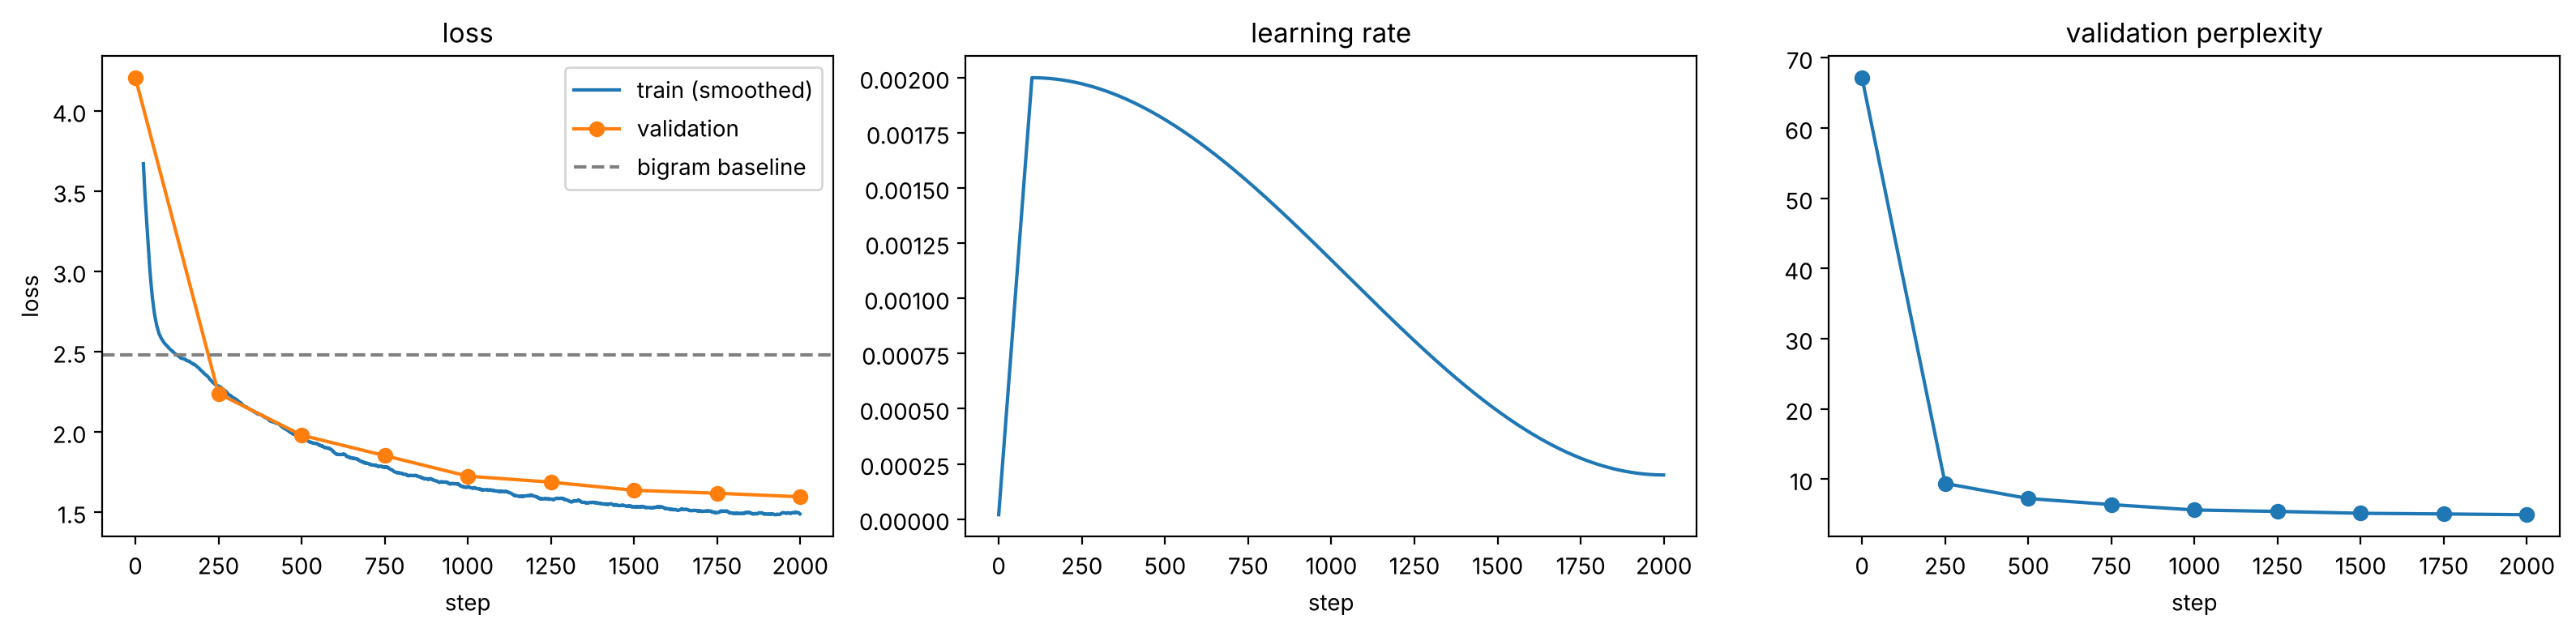

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
k = 25
sm = np.convolve(hist["train"], np.ones(k) / k, mode="valid")
ax[0].plot(hist["iter"][k - 1:], sm, label="train (smoothed)")
ax[0].plot(hist["eval_iter"], hist["eval_val"], "o-", label="validation")
ax[0].axhline(bigram_val, color="gray", linestyle="--", label="bigram baseline")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("loss")
ax[1].plot(hist["iter"], hist["lr"]); ax[1].set_xlabel("step"); ax[1].set_title("learning rate")
ax[2].plot(hist["eval_iter"], np.exp(hist["eval_val"]), "o-"); ax[2].set_xlabel("step"); ax[2].set_title("validation perplexity")
plt.tight_layout(); plt.show()

## Evaluate the best checkpoint

The training loop saved the checkpoint with the lowest validation loss. Load it, measure the loss on a larger sample of batches, and compare with the baselines.

In [13]:
ck = torch.load(os.path.join(tc.out_dir, "ckpt.pt"), map_location=device)
best = GPT(GPTConfig(**ck["cfg"])).to(device)
best.load_state_dict(ck["model"])
best.eval()
ev = estimate_loss(best, data, best.cfg.block_size, 32, 200, make_context(tc.dtype, device), device)
print(f"checkpoint from step {ck['iter']}")
print(f"train loss {ev['train']:.4f} | val loss {ev['val']:.4f} | val perplexity {math.exp(ev['val']):.2f}")
print(f"uniform {math.log(data.vocab_size):.4f} | bigram {bigram_val:.4f} | GPT {ev['val']:.4f}")
assert ev["val"] < bigram_val - 0.3, "the transformer should clearly beat the bigram model"

checkpoint from step 2000
train loss 1.3960 | val loss 1.6015 | val perplexity 4.96
uniform 4.1744 | bigram 2.4819 | GPT 1.6015


## Generate text

Samples at three temperatures. Low temperature is safe and repetitive, high temperature is more creative and more error prone.

In [14]:
start = torch.tensor([data.start_ids], dtype=torch.long, device=device)
for temp, top_k in ((0.6, None), (0.8, 40), (1.0, None)):
    torch.manual_seed(SEED)
    out = best.generate(start, 400, temperature=temp, top_k=top_k)[0].tolist()
    print(f"----- temperature {temp}, top_k {top_k} -----")
    print(data.decode(out))
    print()

----- temperature 0.6, top_k None -----

Can to the death in the life of this of mouth,
And shall be the strength of nothing of fair,
And said you will as your and despited now.

CAMILLO:
Then you are the comfort, then the shall speak,
Or being right ship of the maid and send ears;
And not be passion of the king of his hand.

POLIXENES:
The very of what your not tongue the conspition:
What do did this common heart of me.

First Murderer:



----- temperature 0.8, top_k 40 -----

Can to the death? The roos nate with of mouth,
Sir, he storm with this baze nothing confice:
Speak, thy more shall company Bohemia,
Be no deliver power and a fit death,
For the common that the soldies that thou his mercy
And heart, till I sell sense' to his daughter,
Which is flatter taughter in them very of wears,
And to the devile conspition: how is your done,
How dispation the mouths in head.





----- temperature 1.0, top_k None -----

Can man thee; 'twick's not nate with of mouth:
Sir, he storm with this baze nothing cold and his said
your fash soldien for poor from grace. If them:
What paint to a virtue to take; and with pleasure it.
They mays he hand my heart, till I sell;
And 'be possidence; and with wor.

Clown:
I am well tempt put of wears, I am this son that.
And therefore eyes now. Ay, what's part of me.

First Murderer:



In [15]:
if data.kind == "char":
    prompt = "ROMEO:\n"
    ids = torch.tensor([data.encode(prompt)], dtype=torch.long, device=device)
    torch.manual_seed(SEED)
    print(data.decode(best.generate(ids, 500, temperature=0.8, top_k=40)[0].tolist()))

ROMEO:
Can man thee weary on room as earn and
Though thy fear storm with this baze.

POLIXENES:
Ay, and if thy more shall come to Bolingbroke.

MENENIUS:
This is this this father, then these that she's love of heaven
This mercy, my lord, tell me sleen's black pass.

RICHARD:
What, I cannot world him in them very of wears,
I am this secured confest her how instrike.

CLAUDIO:
I have now know.

AUTOLYCUS:
How many go minter:
It is away I clook so if by your ruil.

GLOUCESTER:
The queen such and dug that 


## A measurable view of quality

Loss is hard to read by itself. One simple, objective check is the fraction of generated words that are real words from the training text. A model that only knows which letter follows which letter makes many nonsense words. A transformer with a context of a hundred or more characters should produce mostly real words.

In [16]:
train_text = data.decode(data.train.tolist())
vocab_words = set(re.findall(r"[a-z']+", train_text.lower()))

def valid_word_rate(s):
    words = re.findall(r"[A-Za-z']+", s)[1:-1]            # drop the first and last words, which may be cut off
    return sum(w.lower() in vocab_words for w in words) / max(len(words), 1), len(words)

n_gen = 6000
torch.manual_seed(SEED)
gpt_text = data.decode(best.generate(start, n_gen, temperature=0.8, top_k=40)[0].tolist())
bi_text = data.decode(sample_bigram(P_bigram, n_gen, data.start_ids))
real_text = train_text[20000:20000 + n_gen]
for name, s in (("real Shakespeare", real_text), ("GPT", gpt_text), ("bigram", bi_text)):
    rate, n = valid_word_rate(s)
    print(f"{name:18s}: {rate * 100:5.1f}% of {n} words are real words")
rate_gpt, _ = valid_word_rate(gpt_text); rate_bi, _ = valid_word_rate(bi_text)
assert rate_gpt > rate_bi + 0.2

real Shakespeare  : 100.0% of 1079 words are real words
GPT               :  90.1% of 1161 words are real words
bigram            :  18.9% of 1103 words are real words


## Look inside: attention patterns

The heatmaps show, for one layer, how much each character (row) looks at each earlier character (column). The upper triangle is empty because of the causal mask.

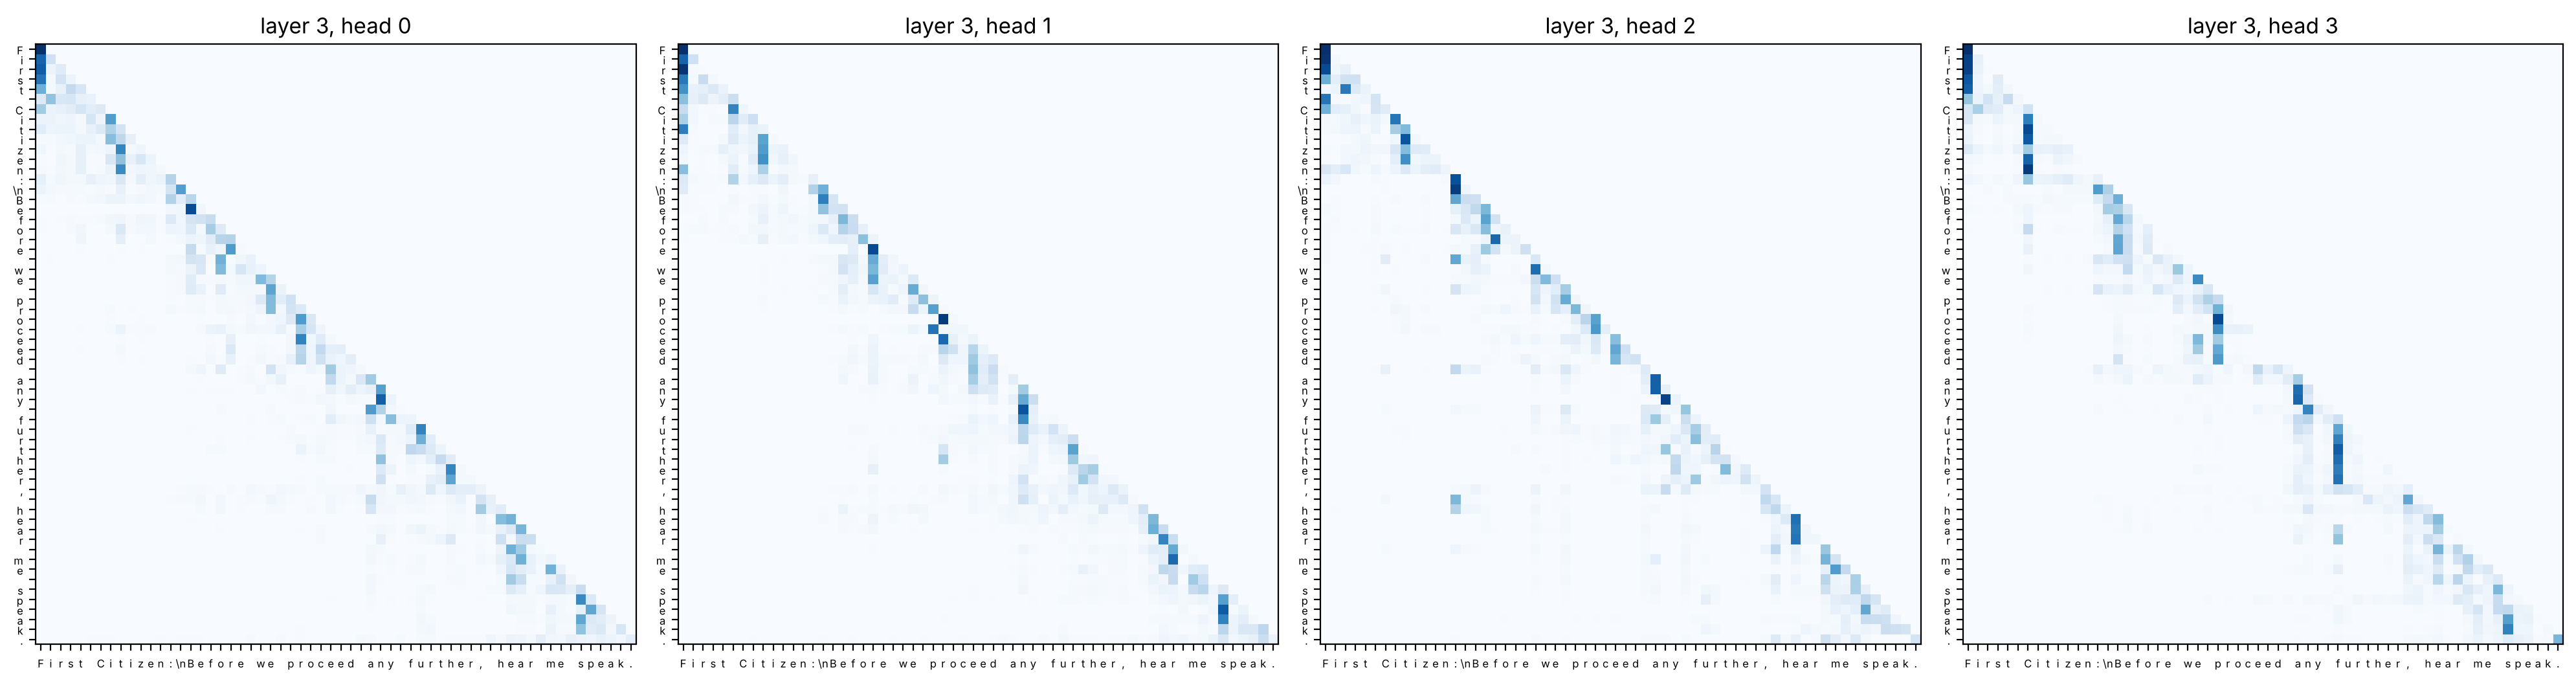

In [17]:
if data.kind == "char":
    snippet = "First Citizen:\nBefore we proceed any further, hear me speak."
else:
    snippet = None
if snippet is not None:
    ids = torch.tensor([data.encode(snippet)], dtype=torch.long, device=device)
    for blk in best.blocks:
        blk.attn.keep_att = True
    with torch.no_grad():
        best(ids)
    layer = len(best.blocks) - 1
    att = best.blocks[layer].attn.att[0].float().cpu()
    labels = [c.replace("\n", "\\n") for c in snippet]
    n_show = min(4, att.shape[0])
    fig, axes = plt.subplots(1, n_show, figsize=(5 * n_show, 5))
    for h in range(n_show):
        axes[h].imshow(att[h], cmap="Blues")
        axes[h].set_xticks(range(len(labels))); axes[h].set_xticklabels(labels, fontsize=6)
        axes[h].set_yticks(range(len(labels))); axes[h].set_yticklabels(labels, fontsize=6)
        axes[h].set_title(f"layer {layer}, head {h}")
    plt.tight_layout(); plt.show()
    for blk in best.blocks:
        blk.attn.keep_att = False

## Summary

In [18]:
rate_gpt, _ = valid_word_rate(gpt_text)
print(f"device: {device}")
print(f"model: {model.num_params() / 1e6:.2f}M parameters, {cfg.n_layer} layers, {cfg.n_head} heads, {cfg.n_embd} dimensions, context {cfg.block_size}")
print(f"training: {tc.max_iters} steps, effective batch {tc.batch_size * tc.grad_accum_steps} sequences ({tc.batch_size} x {tc.grad_accum_steps} accumulation), {hist['seconds'] / 60:.1f} minutes")
print(f"validation loss {ev['val']:.3f} (bigram baseline {bigram_val:.3f}, uniform {math.log(data.vocab_size):.3f})")
print(f"generated words that are real: {rate_gpt * 100:.0f}% (bigram {rate_bi * 100:.0f}%)")

device: cpu
model: 0.82M parameters, 4 layers, 4 heads, 128 dimensions, context 128
training: 2000 steps, effective batch 64 sequences (32 x 2 accumulation), 27.6 minutes
validation loss 1.601 (bigram baseline 2.482, uniform 4.174)
generated words that are real: 90% (bigram 19%)
